# Quarter 2: the nudges, the math and the decision rules

This notebook explains what the Quarter 2 pilots actually do to Stable Diffusion 1.5 and how every decision is
made, using the saved results of pilot 2 (`outputs/q2_pilot2/`, produced by `dsmlp_pilot2.sh`). It does not load
Stable Diffusion; the code that generates images is `sd_branch.py`, and the line numbers below refer to it.

1. How Stable Diffusion takes one step, and where CFG enters
2. The three nudges (global, targeted, placebo) as formulas
3. Where we nudge: the saved checkpoints and their noise levels
4. Scoring an image and the outcome label $U$
5. How strengths are chosen (dev sweep), and the fixed-policy vs. oracle comparison
6. Real examples: a repaired and a harmed image
7. Pilot 2 numbers and what pilot 3 tests

In [1]:
import csv, json, sys
from collections import Counter, defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

sys.path.insert(0, ".")          # run from quarter2/
import analyze as A

OUT = Path("../../outputs/q2_pilot2")
TASKS = {"two_object": "two_object_prompts.json", "counting": "counting_prompts.json"}
prompts = {t: {p["id"]: p for p in json.load(open(f))} for t, f in TASKS.items()}
print({t: len(p) for t, p in prompts.items()}, "prompts;", "outputs found:", OUT.exists())

{'two_object': 24, 'counting': 24} prompts; outputs found: True


## 1. One step of Stable Diffusion, and CFG

Stable Diffusion works on a 4×64×64 **latent** $z$ (the VAE compresses a 512×512 image 8× per side). Sampling
starts from Gaussian noise $z_{30}$ and makes 30 DDIM updates, $z_{30} \to z_{29} \to \dots \to z_0$; the VAE then
decodes $z_0$ into the image.

At each step the U-Net predicts the **noise** in $z_t$, once without the text and once with it:

$$\epsilon_u = \epsilon_\theta(z_t, t, \varnothing), \qquad \epsilon_c = \epsilon_\theta(z_t, t, c).$$

Classifier-free guidance combines them with weight $w = 7.5$ (SD 1.5's default):

$$\hat\epsilon = \epsilon_u + w\,(\epsilon_c - \epsilon_u).$$

This is Quarter 1's Equation 1 written for noise instead of the clean image. In Quarter 1's notation
$x = x_1 + \sigma x_0$, so the clean-image estimate is $D = x - \sigma\,\epsilon$, and CFG on $\epsilon$ is
the same as CFG on $D$:
$D_u + w(D_c - D_u) = x - \sigma\,[\epsilon_u + w(\epsilon_c - \epsilon_u)]$.

The DDIM update (eta 0, deterministic) first turns $\hat\epsilon$ into a clean-latent estimate, then steps to
the next noise level:

$$\hat z_0 = \frac{z_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}}, \qquad
z_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat z_0 + \sqrt{1-\bar\alpha_{t'}}\,\hat\epsilon .$$

**Every nudge below adds an extra term $e$ to $\hat\epsilon$ for a few steps.** Through the first formula, that
moves the model's current guess of the clean image by
$$\Delta \hat z_0 = -\frac{\sqrt{1-\bar\alpha_t}}{\sqrt{\bar\alpha_t}}\, e = -\sigma_t\, e,$$
so a nudge is literally "push the predicted final image in direction $-e$", with a bigger effect at high
noise (large $\sigma_t$). In code: `denoise()` in `sd_branch.py`.

## 2. The nudges

All nudges last $N$ steps (3 unless written `:8`) starting right after a saved checkpoint, then sampling
continues normally with $w = 7.5$. Size is reported as **pulse size** $= \lVert e \rVert / \lVert \hat\epsilon \rVert$,
averaged over the pulse steps (the `rel_size` field).

**Global pulse, `global:W`.** Use CFG weight $W$ instead of 7.5:
$$e_{\text{global}} = (W - 7.5)\,(\epsilon_c - \epsilon_u).$$
It pushes harder toward *everything* in the prompt. Cost: no extra U-Net calls.

**Targeted pulse, `targeted:λ`.** Push away from specific wrong versions of the prompt, the
**counterfactuals** $c'_1, \dots, c'_k$:
$$e_{\text{targeted}} = \lambda\,\Big(\epsilon_c - \tfrac1k \textstyle\sum_j \epsilon_\theta(z_t, t, c'_j)\Big).$$
It is CFG again, but measured against a near-miss prompt instead of the empty prompt, so it mainly carries
what *distinguishes* the request from the mistake. Cost: $k$ extra U-Net calls per pulse step.

| task | prompt | counterfactuals (what we push away from) |
| --- | --- | --- |
| relation (pilot 1) | A red mug to the left of a blue bowl. | A red mug to the right of a blue bowl. |
| two objects | A photo of a cat and a clock. | A photo of a cat. / A photo of a clock. |
| counting | A photo of three apples. | A photo of two apples. / A photo of four apples. |

**Placebo pulse, `placebo:M`** (pilot 3). A random Gaussian direction $d$ with no meaning, scaled to the same
kind of size:
$$e_{\text{placebo}} = M\,\lVert\hat\epsilon\rVert\,\frac{d}{\lVert d\rVert}, \qquad d \sim \mathcal N(0, I),$$
with $d$ fixed by (seed, checkpoint, step) so it is reproducible. It changes the image without aiming at the
prompt: the control for "any re-roll of the image".

**No action, `none:0`.** Resume from the checkpoint with nothing added. It must reproduce the original image
exactly (it does: max pixel difference 0), which shows that resuming from a saved latent adds no noise of its
own.

In [2]:
# The counterfactuals actually used, straight from the prompt files
for t in TASKS:
    p = next(iter(prompts[t].values()))
    print(f"{t:10s} {p['prompt']!r:40s} -> {p['counterfactuals']}")

two_object 'A photo of a cat and a clock.'          -> ['A photo of a cat.', 'A photo of a clock.']
counting   'A photo of two apples.'                 -> ['A photo of an apple.', 'A photo of three apples.']


## 3. Where we nudge: checkpoints 6, 15 and 24

The baseline run saves $z$ after 6, 15 and 24 of the 30 updates. Every branch restarts from one of these saved
latents, never from another branch, so the branch and the original differ **only** by the nudge.

| saved after step | next timestep $t$ | noise level $\sigma_t = \sqrt{(1-\bar\alpha_t)/\bar\alpha_t}$ | what is still being decided |
| --- | --- | --- | --- |
| 0 (start) | 958 | 11.5 | everything |
| 6 | 760 | 4.3 | layout, how many objects, which objects |
| 15 | 463 | 1.4 | shapes and parts |
| 24 | 166 | 0.49 | texture and fine detail |

(SD's latent $\sigma$ is on a different scale from Quarter 1's CIFAR-10 pixels, so only the order matters.)
Quarter 1 found the class is decided at middle noise; here the same idea predicts that nudges at step 6 change
the most and nudges at step 24 almost nothing, which is what the image-change numbers show.

## 4. Scoring an image, and the outcome label $U$

Nobody looks at the images during a run; `evaluate.py` scores them automatically:

- **Objects:** OWLv2, an open-vocabulary detector, scores boxes for "a photo of a *cat*". An object counts as
  present if its best box scores at least 0.2.
- **Counting:** the number of non-overlapping boxes (IoU < 0.5) scoring at least 0.2 must equal the requested
  count.
- (Pilot 1 also used CLIP for colors and box centers for left/right.)

$R_{\text{all}}(x) = 1$ if every check passes. For a branch with action $a$ from checkpoint $k$ of trajectory $i$:
$$U_i(k, a) = R_{\text{all}}\big(x_i^{(k,a)}\big) - R_{\text{all}}\big(x_i^{\text{none}}\big) \in \{-1, 0, +1\}:$$
**repair** (+1), **harm** (−1) or no change (0). This paired difference is the quantity a future predictor
would have to predict from $z_k$.

In [3]:
# Pilot 2 baseline success, per prompt type, from the saved scores
for t, pf in TASKS.items():
    base, br = A.load(OUT / t / "main", pf, 0.2)
    print(f"{t:10s} {len(base)} baselines, success {A.rate(base):.1%};  {len(br)} branches")

two_object 192 baselines, success 74.5%;  1152 branches
counting   192 baselines, success 41.1%;  1152 branches


## 5. How decisions are made

### 5a. Choosing the strength (dev sweep), decided before seeing the main results
Strengths are chosen on **separate dev prompts** (6 per type × 4 seeds, different objects) so the main
prompts are not used to tune the method. Every candidate runs from all 3 checkpoints, and the rule is:

$$\text{pick}(\text{type}) = \arg\max_{\text{strength, length}}\ \overline{U}_{\text{dev}}, \quad \text{ties} \to \text{the weaker, shorter one.}$$

Below is the pilot 2 sweep, exactly as the pod printed it.

In [4]:
for t in TASKS:
    print(f"--- {t}: picked {(OUT / t / 'main' / 'actions.txt').read_text().strip()}")
    print((OUT / t / "dev" / "pick.txt").read_text())

--- two_object: picked global:14,targeted:15
global:10  n=72  success 69.4%  mean U +0.028  repairs 2  harms 0  pulse size 0.041
global:14  n=72  success 70.8%  mean U +0.042  repairs 3  harms 0  pulse size 0.106
global:14:8  n=72  success 69.4%  mean U +0.028  repairs 2  harms 0  pulse size 0.108
global:20  n=72  success 70.8%  mean U +0.042  repairs 3  harms 0  pulse size 0.202
global:20:8  n=72  success 69.4%  mean U +0.028  repairs 2  harms 0  pulse size 0.204
none:0  n=72  success 66.7%  mean U +0.000  repairs 0  harms 0  pulse size 0.000
targeted:15  n=72  success 68.1%  mean U +0.014  repairs 2  harms 1  pulse size 0.145
targeted:40  n=72  success 68.1%  mean U +0.014  repairs 2  harms 1  pulse size 0.378
targeted:40:8  n=72  success 66.7%  mean U +0.000  repairs 2  harms 2  pulse size 0.354
targeted:80  n=72  success 66.7%  mean U +0.000  repairs 3  harms 3  pulse size 0.771

--- counting: picked global:20,targeted:15
global:10  n=72  success 37.5%  mean U -0.042  repairs 0  ha

Note how thin this is: with 72 dev branches per candidate, the winner is decided by 1–3 repairs. That is
why the main results report each action separately rather than trusting the pick.

### 5b. Fixed policy vs. hindsight oracle (the key number)
A **policy** is either "do nothing" or one (checkpoint, action) pair applied to every image. For trajectories
$i = 1..n$:
$$\text{fixed}(p) = \frac1n \sum_i R_i(p), \qquad
\text{oracle} = \frac1n \sum_i \max_p R_i(p).$$
The oracle picks the best option **per image, in hindsight**. It is not a method; it is the ceiling a perfect
predictor could reach with this menu. The **gap** $\text{oracle} - \max_p \text{fixed}(p)$ is the room that
per-image choice could add over one rule.

The 95% interval resamples **prompts** with replacement (2,000 times), keeping all seeds and branches of a
prompt together, because images of the same prompt are not independent.

### 5c. Go/no-go, decided before the pilots
| gap | meaning |
| --- | --- |
| < ~5 points | weak case for choosing per image |
| ~10+ points | strong reason to try predicting the benefit |

### 5d. The placebo test (pilot 3)
Seven endings per image means the oracle can find a success by luck, as in "best of 7 rolls". Pilot 3 compares
the oracle over the 6 real branches with the oracle over 6 placebo branches:
$$\Delta = \text{oracle}_{\text{real}} - \text{oracle}_{\text{placebo}}.$$
$\Delta \approx 0$: the gain is re-rolling, and nothing is targeted. $\Delta$ clearly $> 0$: the real nudges
repair in ways a random push does not, and predicting them is worth trying.

In [5]:
# Recompute the pilot 2 table from the saved scores
rows = []
for t, pf in TASKS.items():
    base, br = A.load(OUT / t / "main", pf, 0.2)
    res = A.outcomes(base, br)
    traj = A.policies(base, res)
    po = {r["key"]: r["prompt_id"] for r in base}
    fixed, best, oracle = A.summarize(traj, po)
    lo, hi = A.bootstrap(traj, po, n=500)
    cats = Counter(r["cat"] for r in res)
    rows.append((t, fixed["none"], fixed[best], best, oracle, oracle - fixed[best], lo, hi, cats))
for t, none, bf, best, orc, gap, lo, hi, cats in rows:
    print(f"{t:10s} none {none:.1%} | best fixed {bf:.1%} {best} | oracle {orc:.1%} | "
          f"gap {100*gap:.1f} pts [{100*lo:.1f}, {100*hi:.1f}] | repairs {cats['repair']} harms {cats['harm']}")

two_object none 74.5% | best fixed 76.0% (24, 'global:14') | oracle 81.8% | gap 5.7 pts [2.1, 8.3] | repairs 30 harms 21
counting   none 41.1% | best fixed 43.2% (6, 'targeted:15') | oracle 51.6% | gap 8.3 pts [4.2, 10.9] | repairs 35 harms 28


## 6. Real examples

One trajectory per type that some branch repaired: the original image, then all six branches (3 checkpoints ×
2 nudges), each with its automated verdict. Look at how much each checkpoint changes the picture.

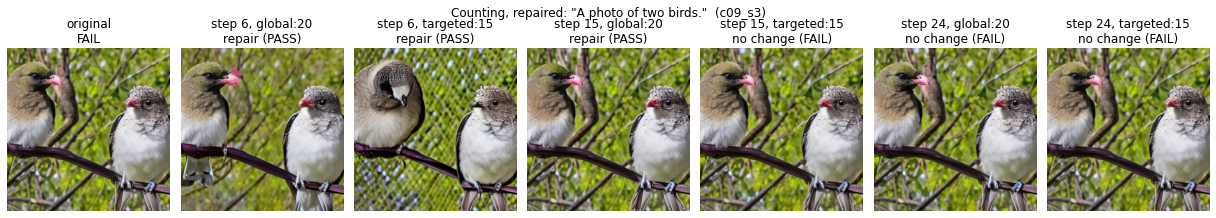

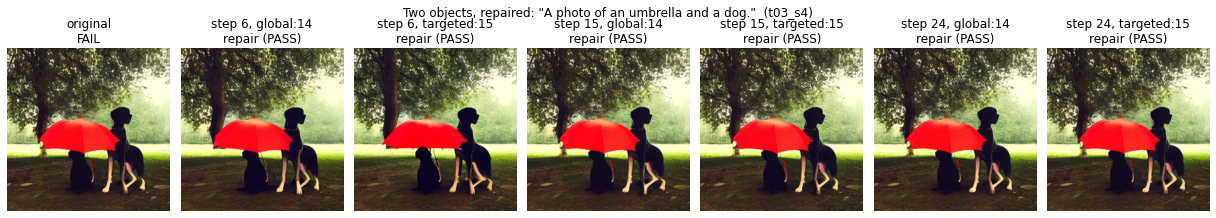

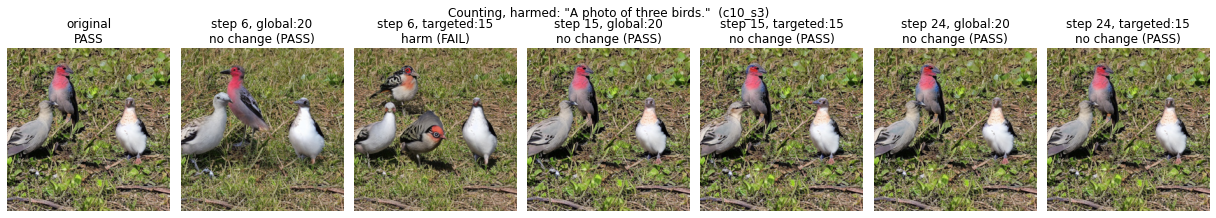

In [6]:
def show(t, pf, want, title):
    run = OUT / t / "main"
    base, br = A.load(run, pf, 0.2)
    res = A.outcomes(base, br)
    by = defaultdict(list)
    for r in res:
        by[r["base_key"]].append(r)
    b = {x["key"]: x for x in base}
    key = next(k for k, rs in sorted(by.items()) if want(b[k], rs))
    rs = sorted(by[key], key=lambda r: (r["checkpoint"], r["action"]))
    fig, ax = plt.subplots(1, 7, figsize=(17, 3.2), dpi=72)
    p = prompts[t][b[key]["prompt_id"]]
    ax[0].imshow(Image.open(run / b[key]["image"]).resize((256, 256))); ax[0].set_title(f"original\n{'PASS' if b[key]['all'] else 'FAIL'}")
    for a_, r in zip(ax[1:], rs):
        a_.imshow(Image.open(run / r["image"]).resize((256, 256)))
        a_.set_title(f"step {r['checkpoint']}, {A.name(r)}\n{r['cat']} ({'PASS' if r['all'] else 'FAIL'})")
    for a_ in ax: a_.axis("off")
    fig.suptitle(f"{title}: \"{p['prompt']}\"  ({key})"); plt.tight_layout(); plt.show()

countable = lambda x, rs: prompts["counting"][x["prompt_id"]]["object_1"] in ("dog", "apple", "bird")
show("counting", TASKS["counting"], lambda x, rs: countable(x, rs) and any(r["cat"] == "repair" for r in rs), "Counting, repaired")
show("two_object", TASKS["two_object"], lambda x, rs: any(r["cat"] == "repair" for r in rs), "Two objects, repaired")
show("counting", TASKS["counting"], lambda x, rs: countable(x, rs) and any(r["cat"] == "harm" for r in rs), "Counting, harmed")

### What these examples reveal: some "repairs" are the scorer, not the image

In the umbrella example, all six branches look almost the same as the original, yet the original fails and every
branch passes: OWLv2 scored the umbrella 0.05 in the original and about 0.81 in every branch. In the bird
example, whether a background shape counts as a third bird decides pass or fail. Across pilot 2, 92% of counting
flips and 47% of two-object flips involve a score near the 0.2 cutoff (0.1 to 0.3), in the original or the
branch. That is the scorer's sensitivity to small changes, and it inflates the oracle: any small push can flip
a borderline verdict.

This is what the placebo in pilot 3 controls for. A random push flips borderline verdicts just as easily, so
if $\text{oracle}_{\text{real}} \approx \text{oracle}_{\text{placebo}}$, the per-image gain is mostly
scorer noise plus re-rolling. A more stable scorer (or a human check) is needed either way.

## 7. Summary of what we did and what is next

- **Nudges:** for 3 steps after step 6, 15 or 24, add $e$ to the CFG noise prediction:
  global $(W-7.5)(\epsilon_c-\epsilon_u)$, targeted $\lambda(\epsilon_c - \overline{\epsilon_{c'}})$, or
  (pilot 3) placebo, a random direction of fixed relative size.
- **Strengths:** chosen on separate dev prompts by highest mean $U$, ties to the weaker one (two objects:
  global 14 and targeted 15; counting: global 20 and targeted 15).
- **Judgment:** automated checks (OWLv2 boxes), $U$ = branch success minus original success, and the gap
  between the per-image hindsight best and the best single rule, with intervals from resampling prompts.
- **Pilot 2:** gap 5.7 points (two objects) and 8.3 (counting); every single rule repairs about as often as it
  harms.
- **Pilot 3 (running):** the placebo control, seeds 8–15, and counting without books and balloons. Its report
  is `outputs/q2_pilot2/<task>/main/report_pilot3.md`.
- **Still needed:** a blinded hand check of a sample of images, since every number here comes from the
  automated scorer.